# Aurora precipitation-type verification and uncertainty analysis

This is the streamlined **Aurora-only** workflow for the reviewer analysis.

It keeps the established verification design:
- mPING consensus QC ≥ 70%
- verification period: 1 Dec 2021–31 Mar 2022
- exact 00/06/12/18 UTC valid-time matching
- forecast Day 1–7 with **+0 h excluded**
- identical mPING valid times for every forecast day
- nearest Aurora grid cell with a 30-km spatial-distance QC
- EDNN (`ML_ptype`) versus Bourgouin categorical skill

The uncertainty analysis is now focused on the reviewer question. It conditions uncertainty on the **mPING-observed precipitation type**, not the EDNN-predicted class, and compares both **epistemic** and **total predictive uncertainty**.

For each class,
\[
U_{total,k}=U_{aleatoric,k}+U_{epistemic,k}.
\]

The reviewer-facing mechanism test asks whether, for **observed ice pellets and freezing rain**, increasing lead time is accompanied by:

1. decreasing EDNN uncertainty,
2. increasing reassignment to rain/snow rather than mixed phase, and
3. decreasing CSI.

A decline in uncertainty is therefore not interpreted by itself as improved forecast reliability.


In [1]:
from pathlib import Path
import xarray as xr

GFS_DIR = Path("/glade/derecho/scratch/sakor/gfs/processed")

# Pick one initialization
init_dir = GFS_DIR / "2022-02-03T00Z"

files = sorted(init_dir.glob("*"))

print("Directory:", init_dir)
print("\nFiles:")
for f in files[:20]:
    print(" ", f.name)

print(f"\nTotal files: {len(files)}")

# Inspect first NetCDF file
nc_files = sorted(init_dir.glob("*.nc"))

if nc_files:
    f = nc_files[0]

    print("\n" + "=" * 80)
    print("Inspecting:", f)
    print("=" * 80)

    with xr.open_dataset(f, decode_timedelta=False) as ds:
        print(ds)

        print("\nDIMENSIONS")
        print(dict(ds.sizes))

        print("\nCOORDINATES")
        for c in ds.coords:
            print(
                c,
                ds[c].dims,
                ds[c].shape,
                ds[c].values[:5] if ds[c].ndim == 1 else ""
            )

        print("\nDATA VARIABLES")
        for v in ds.data_vars:
            da = ds[v]
            print(
                f"{v:25s}",
                f"dims={da.dims}",
                f"shape={da.shape}",
                f"dtype={da.dtype}"
            )

            if da.size < 10_000_000:
                try:
                    print(
                        "   min =", float(da.min()),
                        "max =", float(da.max())
                    )
                except Exception:
                    pass

Directory: /glade/derecho/scratch/sakor/gfs/processed/2022-02-03T00Z

Files:
  gfs_2022-02-03T00Z_006.nc
  gfs_2022-02-03T00Z_012.nc
  gfs_2022-02-03T00Z_018.nc
  gfs_2022-02-03T00Z_024.nc
  gfs_2022-02-03T00Z_030.nc
  gfs_2022-02-03T00Z_036.nc
  gfs_2022-02-03T00Z_042.nc
  gfs_2022-02-03T00Z_048.nc
  gfs_2022-02-03T00Z_054.nc
  gfs_2022-02-03T00Z_060.nc
  gfs_2022-02-03T00Z_066.nc
  gfs_2022-02-03T00Z_072.nc
  gfs_2022-02-03T00Z_078.nc
  gfs_2022-02-03T00Z_084.nc
  gfs_2022-02-03T00Z_090.nc
  gfs_2022-02-03T00Z_096.nc
  gfs_2022-02-03T00Z_102.nc
  gfs_2022-02-03T00Z_108.nc
  gfs_2022-02-03T00Z_114.nc
  gfs_2022-02-03T00Z_120.nc

Total files: 28

Inspecting: /glade/derecho/scratch/sakor/gfs/processed/2022-02-03T00Z/gfs_2022-02-03T00Z_006.nc


/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


<xarray.Dataset> Size: 10MB
Dimensions:      (lead_time: 1, time: 1, height: 21, latitude: 105,
                  longitude: 237)
Coordinates:
  * lead_time    (lead_time) int32 4B 6
  * time         (time) datetime64[ns] 8B 2022-02-03
  * height       (height) float32 84B 0.0 250.0 500.0 ... 4.5e+03 4.75e+03 5e+03
  * latitude     (latitude) float64 840B 24.0 24.25 24.5 ... 49.5 49.75 50.0
  * longitude    (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    surface      float64 8B ...
    valid_time   (time, lead_time) datetime64[ns] 8B ...
Data variables: (12/36)
    T_HEIGHT     (lead_time, time, height, latitude, longitude) float32 2MB ...
    DPT_HEIGHT   (lead_time, time, height, latitude, longitude) float32 2MB ...
    U_HEIGHT     (lead_time, time, height, latitude, longitude) float32 2MB ...
    V_HEIGHT     (lead_time, time, height, latitude, longitude) float32 2MB ...
    ML_rain      (lead_time, time, latitude, longitude) float32 100kB ...
    ML_crain     (le

In [2]:
# Look at several filenames so we can determine how lead time is encoded
for init in [
    "2021-11-24T00Z",
    "2022-01-01T00Z",
    "2022-02-03T00Z",
    "2022-03-31T00Z",
]:
    p = GFS_DIR / init

    print(f"\n{init}")
    for f in sorted(p.glob("*"))[:10]:
        print(" ", f.name)


2021-11-24T00Z
  gfs_2021-11-24T00Z_006.nc
  gfs_2021-11-24T00Z_012.nc
  gfs_2021-11-24T00Z_018.nc
  gfs_2021-11-24T00Z_024.nc
  gfs_2021-11-24T00Z_030.nc
  gfs_2021-11-24T00Z_036.nc
  gfs_2021-11-24T00Z_042.nc
  gfs_2021-11-24T00Z_048.nc
  gfs_2021-11-24T00Z_054.nc
  gfs_2021-11-24T00Z_060.nc

2022-01-01T00Z
  gfs_2022-01-01T00Z_006.nc
  gfs_2022-01-01T00Z_012.nc
  gfs_2022-01-01T00Z_018.nc
  gfs_2022-01-01T00Z_024.nc
  gfs_2022-01-01T00Z_030.nc
  gfs_2022-01-01T00Z_036.nc
  gfs_2022-01-01T00Z_042.nc
  gfs_2022-01-01T00Z_048.nc
  gfs_2022-01-01T00Z_054.nc
  gfs_2022-01-01T00Z_060.nc

2022-02-03T00Z
  gfs_2022-02-03T00Z_006.nc
  gfs_2022-02-03T00Z_012.nc
  gfs_2022-02-03T00Z_018.nc
  gfs_2022-02-03T00Z_024.nc
  gfs_2022-02-03T00Z_030.nc
  gfs_2022-02-03T00Z_036.nc
  gfs_2022-02-03T00Z_042.nc
  gfs_2022-02-03T00Z_048.nc
  gfs_2022-02-03T00Z_054.nc
  gfs_2022-02-03T00Z_060.nc

2022-03-31T00Z
  gfs_2022-03-31T00Z_006.nc
  gfs_2022-03-31T00Z_012.nc
  gfs_2022-03-31T00Z_018.nc
  gfs_2022-0

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

MPING_PATH="/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"
BASE=Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
AURORA_DIR=BASE/"au_ptype"; OUT=BASE/"verification"; FIG=OUT/"figures_aurora"
OUT.mkdir(parents=True,exist_ok=True); FIG.mkdir(parents=True,exist_ok=True)

START=pd.Timestamp("2021-12-01"); END=pd.Timestamp("2022-04-01")
LAT_MIN,LAT_MAX=24.,50.; LON_MIN,LON_MAX=-125.,-66.
CONSENSUS=70.; MAX_DIST=30.

PTYPE_COLS={"sn_percent":"Snow","ra_percent":"Rain","pl_percent":"Ice Pellet","fzra_percent":"Freezing Rain"}
CLASS_NAMES={0:"Rain",1:"Snow",2:"Ice Pellet",3:"Freezing Rain"}
CLASS_CODES={v:k for k,v in CLASS_NAMES.items()}
CLASS_ORDER=["Rain","Snow","Ice Pellet","Freezing Rain"]; MIXED=["Ice Pellet","Freezing Rain"]
EPI={"Rain":"ML_rain_epi","Snow":"ML_snow_epi","Ice Pellet":"ML_icep_epi","Freezing Rain":"ML_frzr_epi"}
VARS=["ML_ptype","ML_rain","ML_snow","ML_icep","ML_frzr","ML_u",
      "ML_rain_ale","ML_snow_ale","ML_icep_ale","ML_frzr_ale",
      "ML_rain_epi","ML_snow_epi","ML_icep_epi","ML_frzr_epi","BOURG_ptype"]


## 1. Prepare mPING observations

In [2]:
def prepare_mping(path):
    cols=["datetime","lat","lon","report_count","sn_percent","ra_percent","pl_percent","fzra_percent"]
    d=pd.read_parquet(path,columns=cols); d["datetime"]=pd.to_datetime(d["datetime"])
    d=d[(d.datetime>=START)&(d.datetime<END)&d.datetime.dt.hour.isin([0,6,12,18])].copy()
    d=d[d.lat.between(LAT_MIN,LAT_MAX)&d.lon.between(LON_MIN,LON_MAX)].copy()
    pc=list(PTYPE_COLS); d["obs_class"]=d[pc].idxmax(axis=1).map(PTYPE_COLS); d["obs_consensus"]=d[pc].max(axis=1)
    if d.obs_consensus.max()<=1: d["obs_consensus"]*=100
    d=d[d.obs_consensus>=CONSENSUS].reset_index(drop=True); d["obs_id"]=np.arange(len(d))
    return d[["obs_id","datetime","lat","lon","report_count","obs_class","obs_consensus"]]

obs=prepare_mping(MPING_PATH)
print("N =",len(obs)); print(obs.obs_class.value_counts().reindex(CLASS_ORDER)); print(obs.datetime.dt.hour.value_counts().sort_index())


N = 29834
obs_class
Rain             11902
Snow             15894
Ice Pellet        1220
Freezing Rain      818
Name: count, dtype: int64
datetime
0      7682
6      5486
12     5440
18    11226
Name: count, dtype: int64


## 2. Construct identical Day 1–7 verification samples

The 00 UTC forecast at **+0 h is an initialization state and is never evaluated**. For a 00 UTC mPING valid time, Day 1 therefore uses the previous day's +24 h forecast; Day 2 uses +48 h, etc. For 06/12/18 UTC, the corresponding leads are +6/+12/+18 h for Day 1 and increase by 24 h for subsequent forecast days.

In [3]:
def expand_days(obs):
    z=[]
    for day in range(1,8):
        x=obs.copy(); h=x.datetime.dt.hour; x["forecast_day"]=day
        x["lead_hour"]=np.where(h==0,24*day,h+24*(day-1)).astype(int)
        x["init_time"]=x.datetime-pd.to_timedelta(x.lead_hour,unit="h"); z.append(x)
    return pd.concat(z,ignore_index=True)
matches=expand_days(obs)
assert matches.groupby("obs_id").size().eq(7).all() and not (matches.lead_hour==0).any()
print(matches.groupby("forecast_day").lead_hour.apply(lambda x:sorted(x.unique())))


forecast_day
1         [6, 12, 18, 24]
2        [30, 36, 42, 48]
3        [54, 60, 66, 72]
4        [78, 84, 90, 96]
5    [102, 108, 114, 120]
6    [126, 132, 138, 144]
7    [150, 156, 162, 168]
Name: lead_hour, dtype: object


## 3. Collocate mPING with Aurora and apply spatial-distance QC

Each point observation is paired with the nearest Aurora grid point. The 30-km threshold removes pathological nearest-neighbor matches outside the effective model-domain/grid coverage while retaining normal matches expected for an approximately 0.25° grid.

In [4]:
class Collocator:
    def path(self,t,l):
        s=pd.Timestamp(t).strftime("%Y-%m-%dT00Z")
        return AURORA_DIR/s/f"aurora_{s}_{int(l):03d}.nc"
    @staticmethod
    def hav(lat1,lon1,lat2,lon2):
        R=6371.; lat1,lon1,lat2,lon2=map(np.radians,[lat1,lon1,lat2,lon2])
        a=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
        return 2*R*np.arcsin(np.sqrt(a))
    def run(self,m):
        out=[]; groups=m.groupby(["init_time","lead_hour"]); n=len(groups)
        for i,((t,l),g) in enumerate(groups,1):
            p=self.path(t,l)
            if not p.exists(): print("[MISSING]",p); continue
            if i==1 or i%100==0 or i==n: print(f"{i}/{n}: {t} +{l:03d} h, N={len(g)}")
            with xr.open_dataset(p,decode_timedelta=False) as ds:
                q=ds.sel(latitude=xr.DataArray(g.lat.values,dims="obs"),
                         longitude=xr.DataArray(g.lon.values,dims="obs"),method="nearest")
                r=g.reset_index(drop=True).copy()
                r["grid_lat"]=np.asarray(q.latitude); r["grid_lon"]=np.asarray(q.longitude)
                r["grid_distance_km"]=self.hav(r.lat.values,r.lon.values,r.grid_lat.values,r.grid_lon.values)
                r["spatial_match_valid"]=r.grid_distance_km<=MAX_DIST
                for v in VARS:
                    if v in q: r[v]=np.asarray(q[v]).squeeze()
                out.append(r)
        return pd.concat(out,ignore_index=True)

aurora=Collocator().run(matches)
print("Rows:",len(aurora))
print(aurora.grid_distance_km.describe(percentiles=[.5,.9,.95,.99]))
print(">30 km:",(~aurora.spatial_match_valid).sum()," ML -1:",(aurora.ML_ptype==-1).sum())
aurora.to_parquet(OUT/"aurora_mping_collocations.parquet",index=False)


1/3325: 2021-11-24 00:00:00 +168 h, N=8


/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


100/3325: 2021-12-01 00:00:00 +072 h, N=2
200/3325: 2021-12-05 00:00:00 +024 h, N=62
300/3325: 2021-12-08 00:00:00 +120 h, N=18
400/3325: 2021-12-12 00:00:00 +048 h, N=24
500/3325: 2021-12-15 00:00:00 +144 h, N=6
600/3325: 2021-12-19 00:00:00 +072 h, N=34
700/3325: 2021-12-22 00:00:00 +168 h, N=102
800/3325: 2021-12-26 00:00:00 +096 h, N=72
900/3325: 2021-12-30 00:00:00 +024 h, N=106
1000/3325: 2022-01-02 00:00:00 +120 h, N=102
1100/3325: 2022-01-06 00:00:00 +048 h, N=24
1200/3325: 2022-01-09 00:00:00 +168 h, N=74
1300/3325: 2022-01-13 00:00:00 +114 h, N=122
1400/3325: 2022-01-17 00:00:00 +042 h, N=46
1500/3325: 2022-01-20 00:00:00 +138 h, N=44
1600/3325: 2022-01-24 00:00:00 +066 h, N=22
1700/3325: 2022-01-28 00:00:00 +030 h, N=186
1800/3325: 2022-02-01 00:00:00 +006 h, N=8
1900/3325: 2022-02-04 00:00:00 +132 h, N=10
2000/3325: 2022-02-08 00:00:00 +072 h, N=52
2100/3325: 2022-02-12 00:00:00 +018 h, N=84
2200/3325: 2022-02-15 00:00:00 +138 h, N=12
2300/3325: 2022-02-19 00:00:00 +066 h, 

## 4. Common valid sample for EDNN and Bourgouin

In [5]:
v=aurora[aurora.spatial_match_valid & aurora.obs_class.isin(CLASS_ORDER) &
         aurora.ML_ptype.isin(CLASS_NAMES) & aurora.BOURG_ptype.isin(CLASS_NAMES)].copy()
v["obs_code"]=v.obs_class.map(CLASS_CODES).astype(int); v["ML_ptype"]=v.ML_ptype.astype(int); v["BOURG_ptype"]=v.BOURG_ptype.astype(int)
print("Common rows:",len(v)); print(v.groupby("forecast_day").size())


Common rows: 208690
forecast_day
1    29814
2    29806
3    29814
4    29792
5    29814
6    29828
7    29822
dtype: int64


## 5. Aurora precipitation-type skill

In [6]:
def div(a,b): return np.nan if b==0 else a/b
def metrics(o,p,c):
    o=np.asarray(o)==c; p=np.asarray(p)==c
    tp=np.sum(o&p); fn=np.sum(o&~p); fp=np.sum(~o&p); tn=np.sum(~o&~p)
    return dict(N=len(o),Observed=int(tp+fn),Forecast=int(tp+fp),TP=int(tp),FN=int(fn),FP=int(fp),TN=int(tn),
                POD=div(tp,tp+fn),FAR=div(fp,tp+fp),CSI=div(tp,tp+fn+fp),F1=div(2*tp,2*tp+fp+fn),Bias=div(tp+fp,tp+fn))
def table(d,col,method,day="All"):
    x=d if day=="All" else d[d.forecast_day==day]; rows=[]
    for c,n in CLASS_NAMES.items():
        r=metrics(x.obs_code,x[col],c); r.update(Method=method,Forecast_Day=day,Class=n); rows.append(r)
    return pd.DataFrame(rows)
overall=pd.concat([table(v,"ML_ptype","ML"),table(v,"BOURG_ptype","Bourgouin")],ignore_index=True)
daily=pd.concat([table(v,c,m,d) for d in range(1,8) for c,m in [("ML_ptype","ML"),("BOURG_ptype","Bourgouin")]],ignore_index=True)
display(overall[["Method","Class","POD","FAR","CSI","F1","Bias"]].round(3))
daily.to_csv(OUT/"aurora_skill_by_day.csv",index=False)


,Method,Class,POD,FAR,CSI,F1,Bias
0,ML,Rain,0.876,0.162,0.749,0.857,1.045
1,ML,Snow,0.887,0.123,0.789,0.882,1.012
2,ML,Ice Pellet,0.238,0.498,0.192,0.323,0.473
3,ML,Freezing Rain,0.320,0.644,0.203,0.337,0.899
4,Bourgouin,Rain,0.893,0.226,0.708,0.829,1.154
5,Bourgouin,Snow,0.801,0.094,0.740,0.850,0.884
6,Bourgouin,Ice Pellet,0.251,0.509,0.199,0.332,0.512
7,Bourgouin,Freezing Rain,0.399,0.770,0.171,0.292,1.733


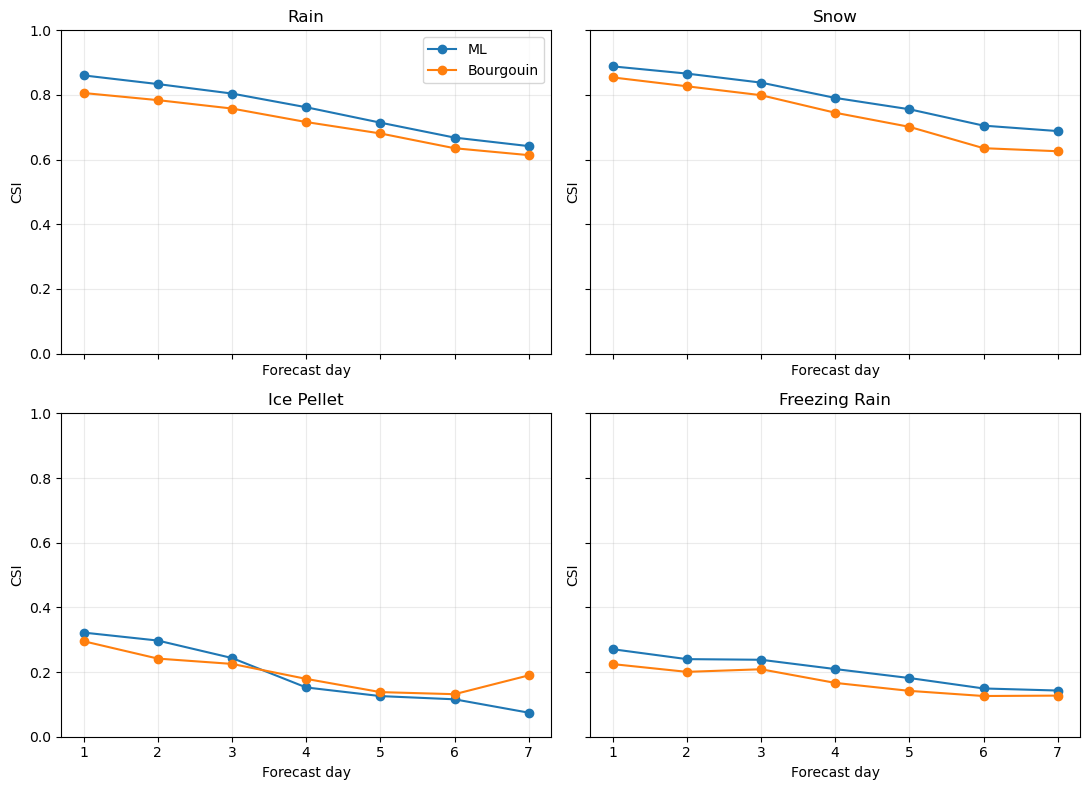

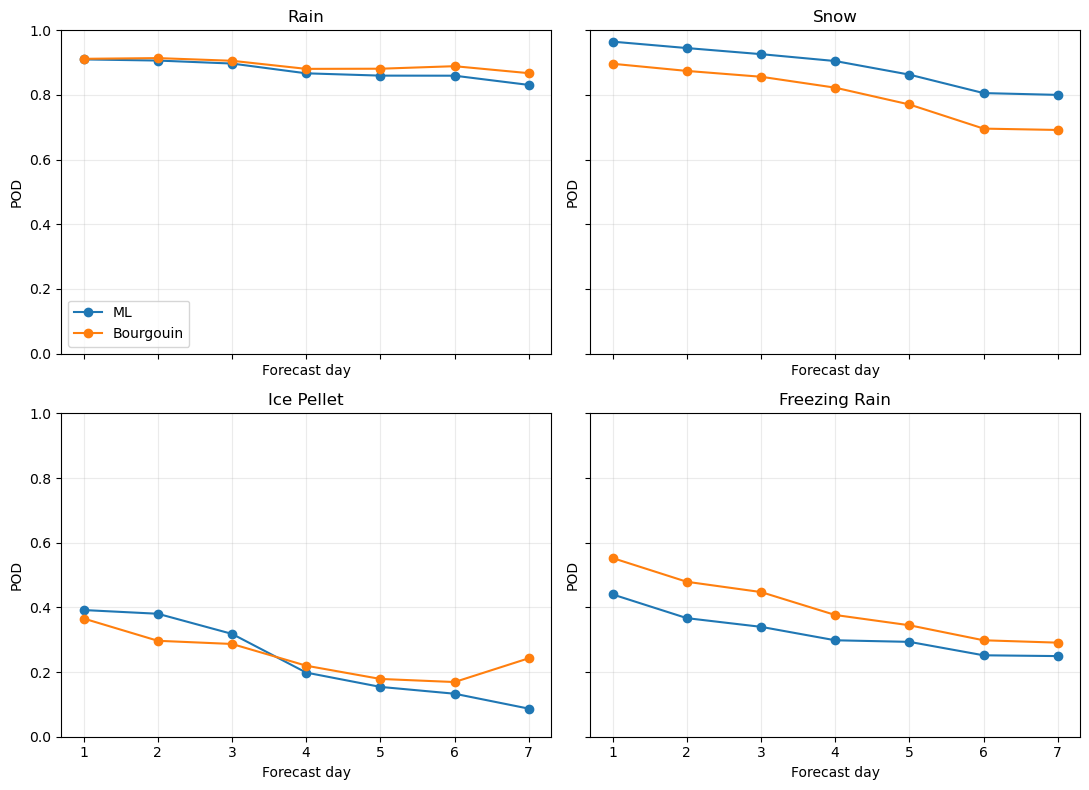

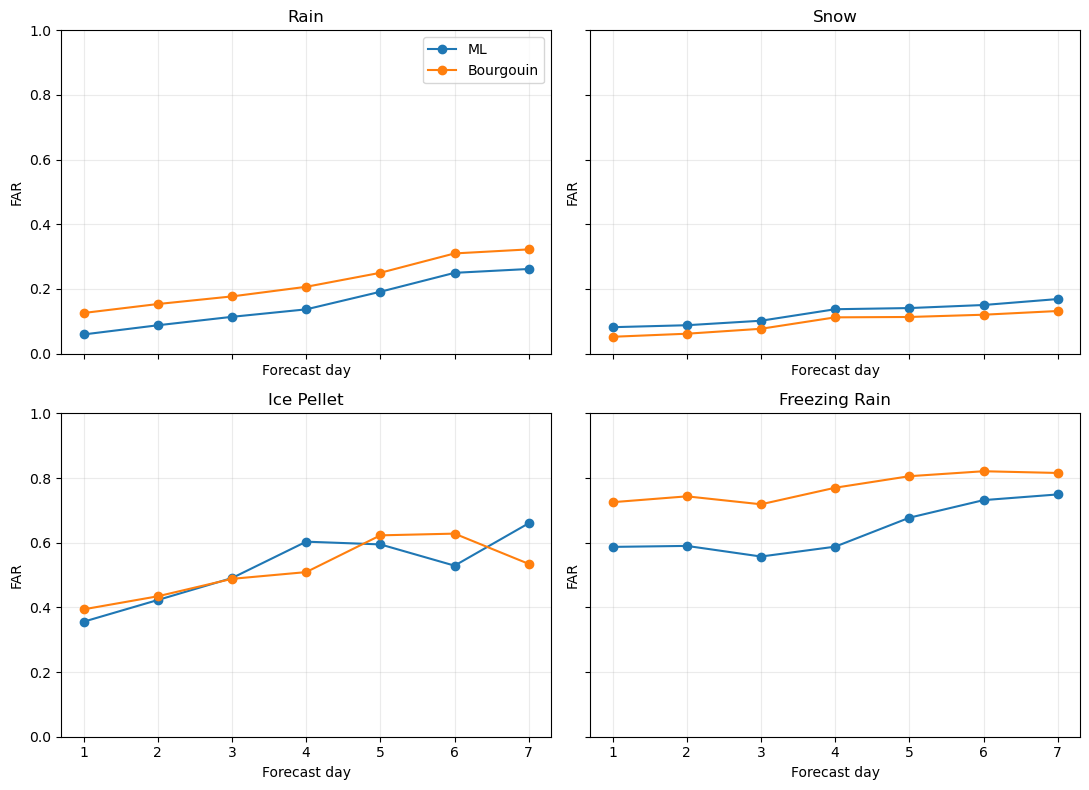

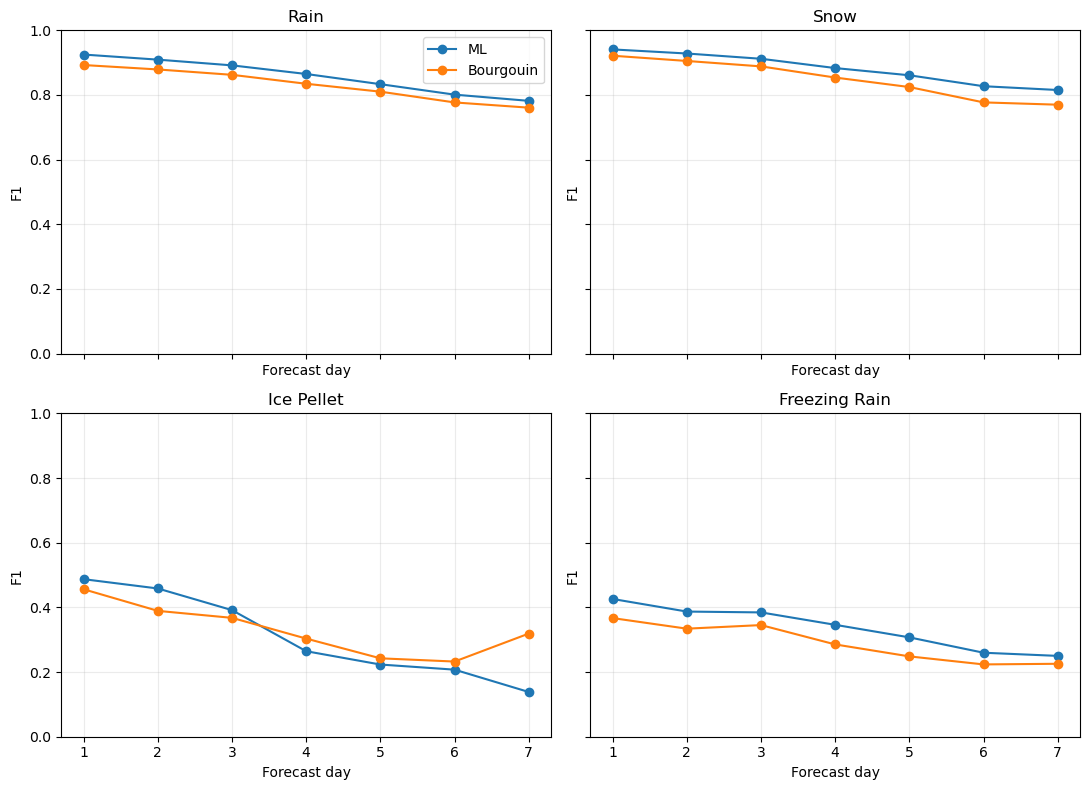

In [7]:
def skill_plot(metric):
    fig,axs=plt.subplots(2,2,figsize=(11,8),sharex=True,sharey=True)
    for ax,ptype in zip(axs.ravel(),CLASS_ORDER):
        for method in ["ML","Bourgouin"]:
            x=daily[(daily.Class==ptype)&(daily.Method==method)]
            ax.plot(x.Forecast_Day,x[metric],marker="o",label=method)
        ax.set_title(ptype); ax.set_xticks(range(1,8)); ax.set_ylim(0,1); ax.grid(alpha=.25); ax.set_xlabel("Forecast day"); ax.set_ylabel(metric)
    axs.ravel()[0].legend(); plt.tight_layout(); plt.show()
for metric in ["CSI","POD","FAR","F1"]: skill_plot(metric)


## 6. Build epistemic and total predictive uncertainty

The EDNN stores class-specific aleatoric and epistemic components. We explicitly reconstruct class-specific total uncertainty as their sum. `ML_u` is retained for inspection, but the class-conditioned analysis below uses the class-specific quantities so that uncertainty can be evaluated for the **mPING-observed class**.

In [8]:
ALE={"Rain":"ML_rain_ale","Snow":"ML_snow_ale","Ice Pellet":"ML_icep_ale","Freezing Rain":"ML_frzr_ale"}
EPI={"Rain":"ML_rain_epi","Snow":"ML_snow_epi","Ice Pellet":"ML_icep_epi","Freezing Rain":"ML_frzr_epi"}
TOTAL={}

for name in CLASS_ORDER:
    col="Utotal_"+name.lower().replace(" ","_")
    v[col]=v[ALE[name]]+v[EPI[name]]
    TOTAL[name]=col

# Basic consistency / range inspection
check=[]
for name in CLASS_ORDER:
    check.append({
        "Class":name,
        "ale_min":v[ALE[name]].min(), "ale_max":v[ALE[name]].max(),
        "epi_min":v[EPI[name]].min(), "epi_max":v[EPI[name]].max(),
        "total_min":v[TOTAL[name]].min(), "total_max":v[TOTAL[name]].max()
    })
display(pd.DataFrame(check).round(6))

if "ML_u" in v:
    print("ML_u summary:")
    display(v["ML_u"].describe().to_frame().T.round(6))

,Class,ale_min,ale_max,epi_min,epi_max,total_min,total_max
0,Rain,0.000551,0.241064,0.0,0.039323,0.000552,0.25
1,Snow,0.000492,0.240845,0.0,0.040166,0.000492,0.25
2,Ice Pellet,0.000492,0.237687,0.0,0.037500,0.000492,0.25
3,Freezing Rain,0.000492,0.237947,0.0,0.039279,0.000492,0.25


ML_u summary:


,count,mean,std,min,25%,50%,75%,max
ML_u,208690.0,0.065565,0.097836,0.001969,0.006508,0.015856,0.074021,1.0


## 7. Observed-class-conditioned uncertainty

This is the key conditioning for the reviewer analysis. For example, the freezing-rain curve uses only cases where **mPING observed freezing rain**, then evaluates the EDNN freezing-rain uncertainty at those same samples.

We summarize the distribution with the median and interquartile range because uncertainty distributions can be skewed.

In [9]:
def observed_uncertainty_stats(kind="epi"):
    source=EPI if kind=="epi" else TOTAL
    rows=[]
    for day in range(1,8):
        d=v[v.forecast_day==day]
        for name in CLASS_ORDER:
            x=d.loc[d.obs_class==name,source[name]].dropna()
            rows.append({
                "forecast_day":day, "Class":name, "uncertainty":kind, "n":len(x),
                "mean":x.mean(), "median":x.median(),
                "q25":x.quantile(.25), "q75":x.quantile(.75)
            })
    return pd.DataFrame(rows)

epi_obs=observed_uncertainty_stats("epi")
total_obs=observed_uncertainty_stats("total")

display(epi_obs[epi_obs.Class.isin(MIXED)].round(6))
display(total_obs[total_obs.Class.isin(MIXED)].round(6))

,forecast_day,Class,uncertainty,n,mean,median,q25,q75
2,1,Ice Pellet,epi,1220,0.009222,0.011387,0.001687,0.014968
3,1,Freezing Rain,epi,818,0.008961,0.009369,0.002977,0.013863
6,2,Ice Pellet,epi,1220,0.009094,0.010804,0.000947,0.015036
7,2,Freezing Rain,epi,818,0.008467,0.008371,0.001681,0.014066
10,3,Ice Pellet,epi,1220,0.007737,0.005325,0.000314,0.014343
11,3,Freezing Rain,epi,818,0.008353,0.008614,0.001289,0.013566
14,4,Ice Pellet,epi,1220,0.005973,0.002842,0.000150,0.012426
15,4,Freezing Rain,epi,818,0.007399,0.006558,0.001026,0.013102
18,5,Ice Pellet,epi,1220,0.005986,0.002693,0.000052,0.012262
19,5,Freezing Rain,epi,818,0.005962,0.002583,0.000128,0.010852


,forecast_day,Class,uncertainty,n,mean,median,q25,q75
2,1,Ice Pellet,total,1220,0.145271,0.180536,0.043379,0.230966
3,1,Freezing Rain,total,818,0.139844,0.151162,0.054471,0.223492
6,2,Ice Pellet,total,1220,0.137207,0.164278,0.030760,0.235027
7,2,Freezing Rain,total,818,0.130596,0.137886,0.040965,0.221226
10,3,Ice Pellet,total,1220,0.115178,0.079696,0.017722,0.219313
11,3,Freezing Rain,total,818,0.124755,0.138317,0.035872,0.204359
14,4,Ice Pellet,total,1220,0.090443,0.054453,0.012238,0.194710
15,4,Freezing Rain,total,818,0.113434,0.088544,0.032021,0.196434
18,5,Ice Pellet,total,1220,0.086907,0.051959,0.007238,0.182200
19,5,Freezing Rain,total,818,0.091588,0.050747,0.011318,0.164162


### Epistemic versus total uncertainty for observed mixed-phase cases

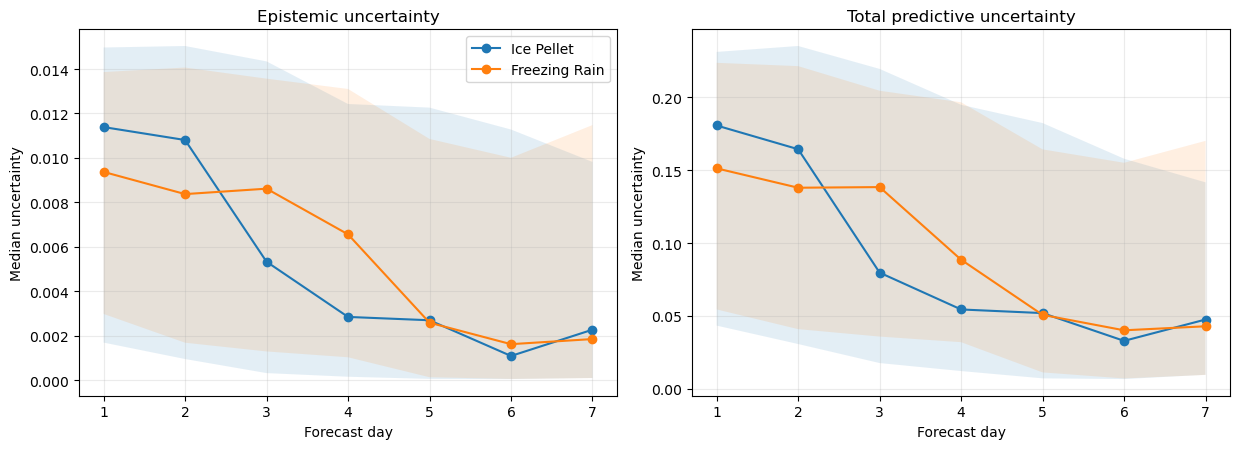

In [10]:
fig,axs=plt.subplots(1,2,figsize=(12.5,4.6),sharex=True)

for ax,stats,label in zip(
    axs,[epi_obs,total_obs],["Epistemic uncertainty","Total predictive uncertainty"]
):
    for p in MIXED:
        x=stats[stats.Class==p]
        ax.plot(x.forecast_day,x["median"],marker="o",label=p)
        ax.fill_between(x.forecast_day,x.q25,x.q75,alpha=.12)
    ax.set_xlabel("Forecast day"); ax.set_ylabel("Median uncertainty")
    ax.set_title(label); ax.set_xticks(range(1,8)); ax.grid(alpha=.25)

axs[0].legend()
plt.tight_layout()
plt.savefig(FIG/"aurora_observed_mixed_epi_vs_total.png",dpi=300,bbox_inches="tight")
plt.show()

## 8. Where do observed mixed-phase cases go?

For each mPING-observed mixed-phase class, EDNN predictions are reduced to two regimes:

- **Rain/Snow** = predicted Rain or Snow
- **Mixed Phase** = predicted Ice Pellet or Freezing Rain

This directly tests whether declining uncertainty occurs while true mixed-phase observations are increasingly absorbed into the dominant rain/snow regimes.

In [17]:
def observed_regime(obs_name):
    x = v[v.obs_class == obs_name].copy()

    x["pred_regime"] = np.where(
        x.ML_ptype.isin([0, 1]),
        "Rain/Snow",
        "Freezing Rain/Ice Pellet"
    )

    z = (
        x.groupby(["forecast_day", "pred_regime"])
        .size()
        .rename("n")
        .reset_index()
    )

    z["fraction"] = (
        z["n"] /
        z.groupby("forecast_day")["n"].transform("sum")
    )

    return z


regime = pd.concat([
    observed_regime("Ice Pellet").assign(Observed="Ice Pellet"),
    observed_regime("Freezing Rain").assign(Observed="Freezing Rain")
], ignore_index=True)

display(
    regime.pivot_table(
        index=["forecast_day", "Observed"],
        columns="pred_regime",
        values="fraction"
    ).round(4)
)

pred_regime                 Freezing Rain/Ice Pellet  Rain/Snow
forecast_day Observed                                          
1            Freezing Rain                    0.6015     0.3985
             Ice Pellet                       0.5918     0.4082
2            Freezing Rain                    0.5575     0.4425
             Ice Pellet                       0.5541     0.4459
3            Freezing Rain                    0.5012     0.4988
             Ice Pellet                       0.4459     0.5541
4            Freezing Rain                    0.4425     0.5575
             Ice Pellet                       0.3164     0.6836
5            Freezing Rain                    0.3545     0.6455
             Ice Pellet                       0.3541     0.6459
6            Freezing Rain                    0.3154     0.6846
             Ice Pellet                       0.3317     0.6683
7            Freezing Rain                    0.3081     0.6919
             Ice Pellet                       0.3344     0.6656

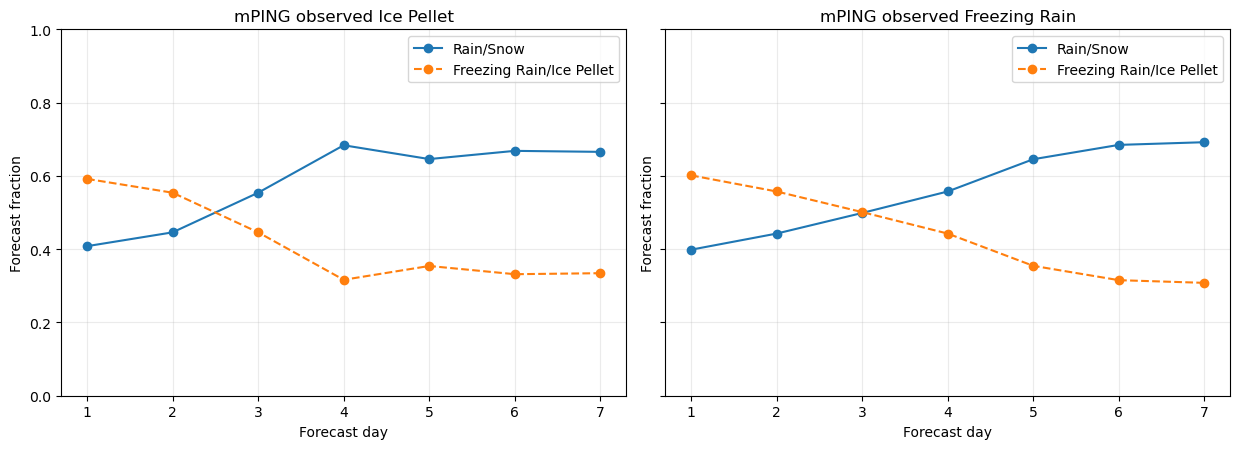

In [18]:
fig, axs = plt.subplots(
    1, 2, figsize=(12.5, 4.6),
    sharex=True, sharey=True
)

for ax, obs_name in zip(axs, ["Ice Pellet", "Freezing Rain"]):
    x = regime[regime.Observed == obs_name]

    for pred_regime, ls in [
        ("Rain/Snow", "-"),
        ("Freezing Rain/Ice Pellet", "--")
    ]:
        y = x[x.pred_regime == pred_regime]

        ax.plot(
            y.forecast_day,
            y.fraction,
            marker="o",
            linestyle=ls,
            label=pred_regime
        )

    ax.set_title(f"mPING observed {obs_name}")
    ax.set_xlabel("Forecast day")
    ax.set_ylabel("Forecast fraction")
    ax.set_ylim(0, 1)
    ax.set_xticks(range(1, 8))
    ax.grid(alpha=.25)
    ax.legend()

plt.tight_layout()

plt.savefig(
    FIG / "aurora_observed_frzr_ip_regime_shift.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

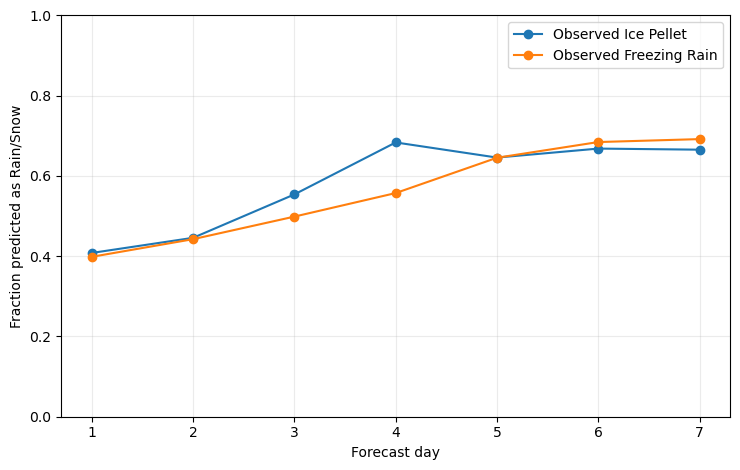

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))

for obs_name in ["Ice Pellet", "Freezing Rain"]:
    x = regime[
        (regime.Observed == obs_name) &
        (regime.pred_regime == "Rain/Snow")
    ]

    ax.plot(
        x.forecast_day,
        x.fraction,
        marker="o",
        label=f"Observed {obs_name}"
    )

ax.set_xlabel("Forecast day")
ax.set_ylabel("Fraction predicted as Rain/Snow")
ax.set_ylim(0, 1)
ax.set_xticks(range(1, 8))
ax.grid(alpha=.25)
ax.legend()

plt.tight_layout()
plt.savefig(
    FIG / "aurora_frzr_ip_to_rain_snow.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 9. Reviewer figure — epistemic uncertainty, regime collapse, and CSI

This is the direct three-panel version of the proposed reviewer response.

**(a)** Epistemic uncertainty for mPING-observed ice pellets and freezing rain.  
**(b)** For those same observed cases, the fraction reassigned to Rain/Snow versus retained as Mixed Phase.  
**(c)** CSI for ice pellets and freezing rain.

Panel (b) is conditioned on the same observed classes as panels (a) and (c); it is **not** the overall Aurora forecast-class distribution.

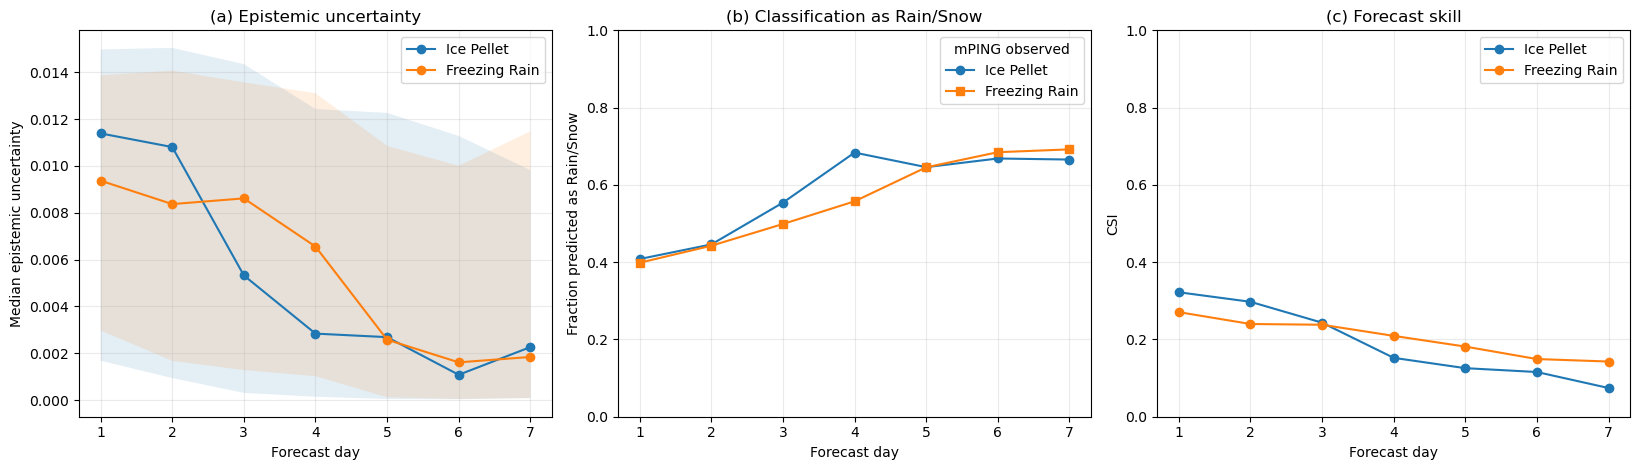

In [20]:
fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.8))

# ============================================================
# (a) Epistemic uncertainty conditioned on mPING observation
# ============================================================

for p in ["Ice Pellet", "Freezing Rain"]:
    x = epi_obs[epi_obs.Class == p]

    axs[0].plot(
        x.forecast_day,
        x["median"],
        marker="o",
        label=p
    )

    axs[0].fill_between(
        x.forecast_day,
        x.q25,
        x.q75,
        alpha=.12
    )

axs[0].set(
    title="(a) Epistemic uncertainty",
    xlabel="Forecast day",
    ylabel="Median epistemic uncertainty"
)
axs[0].legend()
axs[0].grid(alpha=.25)


# ============================================================
# (b) Fraction of observed IP/FRZR predicted as Rain/Snow
# ============================================================

for obs_name, marker in [
    ("Ice Pellet", "o"),
    ("Freezing Rain", "s")
]:
    x = regime[
        (regime.Observed == obs_name) &
        (regime.pred_regime == "Rain/Snow")
    ]

    axs[1].plot(
        x.forecast_day,
        x.fraction,
        marker=marker,
        label=obs_name
    )

axs[1].set(
    title="(b) Classification as Rain/Snow",
    xlabel="Forecast day",
    ylabel="Fraction predicted as Rain/Snow"
)
axs[1].set_ylim(0, 1)
axs[1].legend(title="mPING observed")
axs[1].grid(alpha=.25)


# ============================================================
# (c) EDNN CSI
# ============================================================

for p in ["Ice Pellet", "Freezing Rain"]:
    x = daily[
        (daily.Method == "ML") &
        (daily.Class == p)
    ]

    axs[2].plot(
        x.Forecast_Day,
        x.CSI,
        marker="o",
        label=p
    )

axs[2].set(
    title="(c) Forecast skill",
    xlabel="Forecast day",
    ylabel="CSI"
)
axs[2].set_ylim(0, 1)
axs[2].legend()
axs[2].grid(alpha=.25)


# ============================================================
# Formatting
# ============================================================

for ax in axs:
    ax.set_xticks(range(1, 8))

plt.tight_layout()

plt.savefig(
    FIG / "aurora_reviewer_epi_rainsnow_csi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Reviewer figure using **total predictive uncertainty**

Because the manuscript's primary uncertainty results use total uncertainty, this is the directly analogous figure with panel (a) replaced by

\[
U_{total}=U_{aleatoric}+U_{epistemic}.
\]

Comparing this figure with the epistemic version above shows whether the reviewer-facing conclusion depends on the uncertainty component chosen.

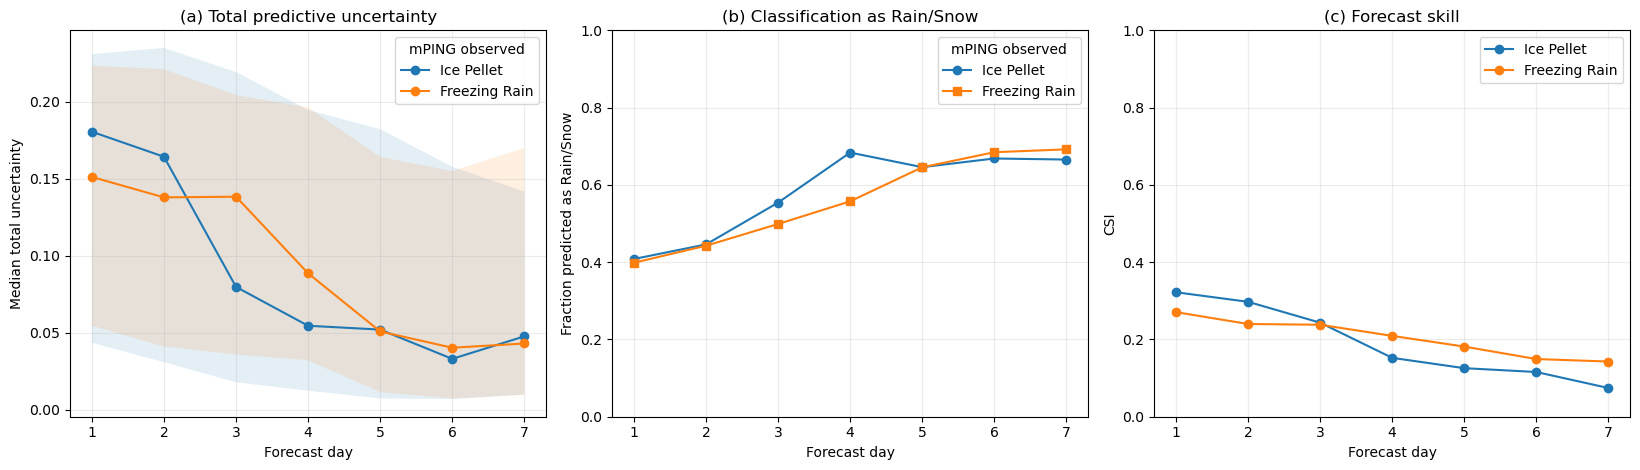

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.8))

# ============================================================
# (a) Total uncertainty conditioned on mPING observation
# ============================================================

for p in ["Ice Pellet", "Freezing Rain"]:
    x = total_obs[total_obs.Class == p]

    axs[0].plot(
        x.forecast_day,
        x["median"],
        marker="o",
        label=p
    )

    axs[0].fill_between(
        x.forecast_day,
        x.q25,
        x.q75,
        alpha=.12
    )

axs[0].set(
    title="(a) Total predictive uncertainty",
    xlabel="Forecast day",
    ylabel="Median total uncertainty"
)
axs[0].legend(title="mPING observed")
axs[0].grid(alpha=.25)


# ============================================================
# (b) Fraction of observed IP/FRZR predicted as Rain/Snow
# ============================================================

for obs_name, marker in [
    ("Ice Pellet", "o"),
    ("Freezing Rain", "s")
]:
    x = regime[
        (regime.Observed == obs_name) &
        (regime.pred_regime == "Rain/Snow")
    ]

    axs[1].plot(
        x.forecast_day,
        x.fraction,
        marker=marker,
        label=obs_name
    )

axs[1].set(
    title="(b) Classification as Rain/Snow",
    xlabel="Forecast day",
    ylabel="Fraction predicted as Rain/Snow"
)
axs[1].set_ylim(0, 1)
axs[1].legend(title="mPING observed")
axs[1].grid(alpha=.25)


# ============================================================
# (c) EDNN class-specific CSI
# ============================================================

for p in ["Ice Pellet", "Freezing Rain"]:
    x = daily[
        (daily.Method == "ML") &
        (daily.Class == p)
    ]

    axs[2].plot(
        x.Forecast_Day,
        x.CSI,
        marker="o",
        label=p
    )

axs[2].set(
    title="(c) Forecast skill",
    xlabel="Forecast day",
    ylabel="CSI"
)
axs[2].set_ylim(0, 1)
axs[2].legend()
axs[2].grid(alpha=.25)


# ============================================================
# Formatting
# ============================================================

for ax in axs:
    ax.set_xticks(range(1, 8))

plt.tight_layout()

plt.savefig(
    FIG / "aurora_reviewer_total_rainsnow_csi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Quantify Day-1 → Day-7 changes

This compact table is intended to support the written reviewer response. It reports changes in both uncertainty definitions, regime collapse, and CSI for each observed mixed-phase class.

In [22]:
rows=[]
for p in MIXED:
    e=epi_obs[epi_obs.Class==p].set_index("forecast_day")["median"]
    t=total_obs[total_obs.Class==p].set_index("forecast_day")["median"]
    r=regime[(regime.Observed==p)&(regime.pred_regime=="Rain/Snow")].set_index("forecast_day")["fraction"]
    s=daily[(daily.Method=="ML")&(daily.Class==p)].set_index("Forecast_Day")["CSI"]
    rows.append({
        "Class":p,
        "Epi_D1":e.get(1,np.nan),"Epi_D7":e.get(7,np.nan),"Epi_change":e.get(7,np.nan)-e.get(1,np.nan),
        "Total_D1":t.get(1,np.nan),"Total_D7":t.get(7,np.nan),"Total_change":t.get(7,np.nan)-t.get(1,np.nan),
        "RainSnow_D1":r.get(1,np.nan),"RainSnow_D7":r.get(7,np.nan),"RainSnow_change":r.get(7,np.nan)-r.get(1,np.nan),
        "CSI_D1":s.get(1,np.nan),"CSI_D7":s.get(7,np.nan),"CSI_change":s.get(7,np.nan)-s.get(1,np.nan)
    })

trend=pd.DataFrame(rows)
display(trend.round(5))

epi_obs.to_csv(OUT/"aurora_uncertainty_epistemic_observed_class.csv",index=False)
total_obs.to_csv(OUT/"aurora_uncertainty_total_observed_class.csv",index=False)
regime.to_csv(OUT/"aurora_observed_mixed_regime.csv",index=False)
trend.to_csv(OUT/"aurora_mixed_phase_reviewer_summary.csv",index=False)

print("Saved reviewer tables to:",OUT)
print("Saved figures to:",FIG)

,Class,Epi_D1,Epi_D7,Epi_change,Total_D1,Total_D7,Total_change,RainSnow_D1,RainSnow_D7,RainSnow_change,CSI_D1,CSI_D7,CSI_change
0,Ice Pellet,0.01139,0.00227,-0.00912,0.18054,0.04756,-0.13297,0.40820,0.66557,0.25738,0.32210,0.07433,-0.24777
1,Freezing Rain,0.00937,0.00185,-0.00752,0.15116,0.04293,-0.10824,0.39853,0.69193,0.29340,0.27068,0.14286,-0.12782


Saved reviewer tables to: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/verification
Saved figures to: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/verification/figures_aurora


## Interpretation

The strongest reviewer-facing evidence is the **joint behavior** of the three diagnostics, not uncertainty alone.

If the results show that, for mPING-observed freezing rain and ice pellets:

- epistemic and/or total uncertainty decreases with lead time,
- the fraction diagnosed as rain/snow increases,
- and CSI simultaneously decreases,

then the declining EDNN uncertainty is consistent with **regime collapse toward dominant precipitation types rather than improving forecast skill**.

The epistemic-versus-total comparison determines whether this behavior is primarily associated with the epistemic component or is also clearly expressed in the manuscript's total predictive uncertainty.

This analysis does **not**, by itself, establish the meteorological cause of the loss of mixed-phase structure in Aurora. That would require direct analysis of the forecast thermodynamic profiles with lead time.
